# Daily OHLCV: return prediction and systematic strategy

**Six-hour interview solution notebook · approximately 200 assets × 10 years**

This notebook implements the project described in the screenshots: inspect daily OHLCV data,
construct backward-looking features, predict next-day returns, and evaluate an explicit trading rule.
No market dataset was supplied. The saved outputs use a **synthetic demonstration**, not interview
data or evidence of a profitable strategy. Set `USE_DEMO=False`, supply the file, map the columns,
and confirm the assumptions in Section 2 to run your dataset.

## 1. Research question, timing, and assumptions

At the end of session $t$, rank assets by their predicted return. Trade at the next open, then
hold until the following open. The executable one-session target is

$$y_{i,t}=\frac{O_{i,t+2}}{O_{i,t+1}}-1.$$

| Item | Decision |
|---|---|
| Information set | OHLCV available through close $t$; all closes synchronized |
| Entry / exit | Open $t+1$ / open $t+2$ |
| Primary prediction metric | Mean **daily cross-sectional RankIC** |
| Trading evaluation | Net Sharpe, drawdown, turnover, costs, and year-by-year stability |
| Portfolio | Long top predictions, short bottom predictions; 50% / 50% notional |
| Validation | Expanding date folds; purge labels that are unavailable at fitting |
| Final test | Last 20% of signal dates, kept out of model selection |

The specification does not identify the asset class or exact definition of “next-day return.”
This implementation assumes positive-priced assets on one trading calendar, in a common currency,
with coherent adjusted OHLC and comparable volume. It is suitable as a starting point for liquid
equities/ETFs after data verification. If the interviewer explicitly requests
$C_{t+1}/C_t-1$, use that as a **forecasting** target, but do not claim an executable close-$t$
strategy after using the complete close-$t$ bar. A next-open-to-next-close target is another valid
choice if the intended strategy closes positions intraday; change both labels and execution together.

Raw continuous futures series require separate contract/roll P&L, multipliers, margin, and possibly
negative-price handling. Carry cannot be inferred reliably from OHLCV alone. None is silently inferred here.

**Six-hour allocation:** 45 min loading/quality; 45 min EDA; 60 min features/labels;
90 min validation/models; 75 min portfolio/robustness; 45 min conclusions and checks.


## 2. Configuration and data loading

Use long format: **one row per asset per session**. Required fields are `date`, `asset`, `open`,
`high`, `low`, `close`, and `volume`. Optional `tradable` must describe eligibility known at the
signal close (for example, point-in-time membership and short availability), not future availability.
CSV works with the base dependencies. Parquet/Excel additionally require the usual reader engine.
If your file is wide, reshape it to this schema before proceeding.

Required packages: **NumPy, pandas, Matplotlib, scikit-learn**. The implementation was checked with
NumPy 2.3.5, pandas 2.2.3, and scikit-learn 1.8.0. No XGBoost or seaborn is required.


In [1]:
from pathlib import Path
import json
import platform
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import sklearn

from sklearn.base import clone
from sklearn.pipeline import make_pipeline
from sklearn.impute import SimpleImputer
from sklearn.preprocessing import StandardScaler
from sklearn.linear_model import Ridge
from sklearn.ensemble import HistGradientBoostingRegressor
from sklearn.model_selection import TimeSeriesSplit
from sklearn.metrics import mean_squared_error, mean_absolute_error
from sklearn.inspection import permutation_importance
from threadpoolctl import threadpool_limits

try:
    display
except NameError:
    display = print

pd.set_option('display.max_columns', 20)
pd.set_option('display.width', 140)
plt.rcParams.update({'figure.figsize': (9, 3.5), 'axes.grid': True, 'grid.alpha': 0.2})
SEED = 42


In [2]:
USE_DEMO = True                  # False for the actual interview dataset
DATA_PATH = Path('market_data.csv')
OUTPUT_DIR = Path('market_project_outputs')

# Map source column names to the seven canonical names. Edit this for your file.
COLUMN_MAP = {
    'Date': 'date', 'Ticker': 'asset', 'Open': 'open', 'High': 'high',
    'Low': 'low', 'Close': 'close', 'Volume': 'volume',
}

# Confirm with the data provider, then change each value to True for a real run.
# If not satisfied, adapt the methodology rather than acknowledging an untrue assumption.
REAL_DATA_CHECKS = {
    'one_synchronized_trading_calendar_and_currency': False,
    'positive_prices_and_coherent_adjusted_OHLC': False,
    'point_in_time_universe_including_exits': False,
    'shorting_and_next_open_execution_reasonable': False,
}

TEST_FRACTION = 0.20
N_FOLDS = 3
WARMUP = 63
MIN_HISTORY = 50
MIN_ASSETS = 20
TOP_FRACTION = 0.20
MAX_ABS_WEIGHT = 0.05
COST_BPS = 5.0                  # per unit of absolute traded notional, not per round trip
BORROW_BPS_ANNUAL = 100.0       # illustrative; replace with asset-specific estimates if available
MIN_DOLLAR_VOLUME = 0.0        # choose a meaningful threshold from development data only
ANNUAL_DAYS = 252
THREADS = 2
MODE = 'SYNTHETIC DEMO' if USE_DEMO else 'REAL DATA'
print(MODE)


SYNTHETIC DEMO


In [3]:
def make_demo(n_dates=1008, n_assets=40, seed=SEED):
    """Synthetic OHLCV with modest persistent/reversing components; execution test only."""
    rng = np.random.default_rng(seed)
    dates = pd.bdate_range('2019-01-02', periods=n_dates)
    common = rng.normal(0, 0.006, n_dates)
    frames = []
    for j in range(n_assets):
        r = np.zeros(n_dates)
        noise = rng.normal(0, 0.012, n_dates)
        beta = rng.uniform(0.7, 1.3)
        for t in range(1, n_dates):
            r[t] = 0.0001 + beta * common[t] - 0.08 * r[t-1] + noise[t]
        close = rng.uniform(20, 100) * np.exp(np.cumsum(r))
        prev_close = np.r_[close[0], close[:-1]]
        open_ = prev_close * np.exp(rng.normal(0, 0.003, n_dates))
        width = rng.uniform(0.001, 0.015, n_dates)
        frames.append(pd.DataFrame({
            'date': dates, 'asset': f'Asset_{j:03d}', 'open': open_,
            'high': np.maximum(open_, close) * (1 + width),
            'low': np.minimum(open_, close) * (1 - width), 'close': close,
            'volume': rng.lognormal(12 + abs(r) * 8, 0.5, n_dates),
        }))
    return pd.concat(frames, ignore_index=True)

if USE_DEMO:
    raw = make_demo()
else:
    if not all(REAL_DATA_CHECKS.values()):
        raise ValueError('Verify REAL_DATA_CHECKS before interpreting a real-data backtest.')
    if not DATA_PATH.exists():
        raise FileNotFoundError(f'Set DATA_PATH to the supplied dataset: {DATA_PATH}')
    if DATA_PATH.suffix.lower() == '.csv':
        raw = pd.read_csv(DATA_PATH)
    elif DATA_PATH.suffix.lower() in {'.parquet', '.pq'}:
        raw = pd.read_parquet(DATA_PATH)
    elif DATA_PATH.suffix.lower() in {'.xlsx', '.xls'}:
        raw = pd.read_excel(DATA_PATH)
    else:
        raise ValueError('Use CSV, Parquet, or Excel; adapt this cell for another format.')
    raw = raw.rename(columns=COLUMN_MAP)

required = ['date', 'asset', 'open', 'high', 'low', 'close', 'volume']
missing_cols = sorted(set(required) - set(raw.columns))
assert not missing_cols, f'Missing columns: {missing_cols}'
assert not raw.columns.duplicated().any(), 'Column mapping produced duplicate names.'
raw = raw.copy()
raw['date'] = pd.to_datetime(raw['date'], errors='raise')
assert raw['date'].dt.tz is None, 'Convert to the agreed session date explicitly.'
assert raw['date'].eq(raw['date'].dt.normalize()).all(), 'Map timestamps to session dates explicitly.'
assert raw[['date', 'asset']].notna().all().all(), 'Missing date or asset identifier.'
raw['asset'] = raw['asset'].astype(str)
for col in required[2:]:
    raw[col] = pd.to_numeric(raw[col], errors='raise')
if 'tradable' not in raw:
    raw['tradable'] = True
assert raw['tradable'].notna().all() and raw['tradable'].isin([True, False, 0, 1]).all()
raw['tradable'] = raw['tradable'].astype(bool)
raw = raw.sort_values(['date', 'asset']).reset_index(drop=True)
print(f'{MODE}: {len(raw):,} rows; {raw.asset.nunique()} assets; {raw.date.nunique()} sessions')
display(raw.head())


SYNTHETIC DEMO: 40,320 rows; 40 assets; 1008 sessions


,date,asset,open,high,low,close,volume,tradable
0,2019-01-02,Asset_000,27.303760,27.695428,26.865156,27.256141,177278.580623,True
1,2019-01-02,Asset_001,48.945737,49.183236,48.498281,48.734756,211807.536126,True
2,2019-01-02,Asset_002,96.216910,96.550499,96.101763,96.435090,122792.210519,True
3,2019-01-02,Asset_003,94.326398,95.376173,93.307314,94.356761,186617.702679,True
4,2019-01-02,Asset_004,43.433477,43.828001,43.044909,43.439380,128002.625316,True


## 3. Data quality and development-only EDA

Reject duplicate keys rather than arbitrarily keeping a row. Reindex to the shared session calendar
before calculating returns: a missing asset-day must remain missing, not become a multi-day return.
The union of supplied session dates is the default calendar; use an official session calendar if an
entire market day is missing. Do not use calendar-day resampling or automatically add holidays.

Split dates before exploratory analysis. All plots, thresholds under consideration, and feature
choices in this section use **development data**. Mechanical validation rules apply unchanged
to test data. Missing bars are never forward-filled; only model features may later receive
training-fold median imputation.


In [4]:
duplicates = raw.duplicated(['date', 'asset'], keep=False)
if duplicates.any():
    display(raw.loc[duplicates].head(10))
    raise ValueError('Resolve duplicate asset-date keys using source metadata.')

calendar = pd.DatetimeIndex(raw['date'].unique()).sort_values()
assets = pd.Index(sorted(raw['asset'].unique()), name='asset')
assert len(calendar) >= 300 and len(assets) >= MIN_ASSETS, 'Need sufficient dates and assets.'
test_start = calendar[int(len(calendar) * (1 - TEST_FRACTION))]
grid = pd.MultiIndex.from_product([calendar, assets], names=['date', 'asset'])
panel = raw.assign(observed=True).set_index(['date', 'asset']).reindex(grid)
panel['observed'] = panel['observed'].eq(True)
panel['tradable'] = panel['tradable'].eq(True)
prices = ['open', 'high', 'low', 'close']

bad_nonpositive = panel[prices].le(0).any(axis=1)
bad_nonfinite = (~np.isfinite(panel[prices]) & panel[prices].notna()).any(axis=1)
bad_order = (
    panel['high'].lt(panel[['open', 'close']].max(axis=1)) |
    panel['low'].gt(panel[['open', 'close']].min(axis=1)) |
    panel['high'].lt(panel['low'])
)
bad_volume = (panel['volume'] < 0) | (~np.isfinite(panel['volume']) & panel['volume'].notna())
bad_bar = bad_nonpositive | bad_nonfinite | bad_order
audit = pd.DataFrame({
    'missing_bar': ~panel['observed'], 'invalid_price_bar': bad_bar,
    'invalid_volume': bad_volume,
}, index=grid)
dev_rows = panel.index.get_level_values('date') < test_start
display(audit.loc[dev_rows].sum().rename('development_count').to_frame())

panel.loc[bad_bar, prices] = np.nan
panel.loc[bad_volume, 'volume'] = np.nan
close = panel['close'].unstack('asset')
open_ = panel['open'].unstack('asset')
high = panel['high'].unstack('asset')
low = panel['low'].unstack('asset')
volume = panel['volume'].unstack('asset')
tradable = panel['tradable'].unstack('asset')
ret_1 = close.pct_change(fill_method=None)

# Flags are for investigation, not automatic deletion of genuine market moves.
unchanged = close.eq(close.shift(1)) & close.notna()
stale_5 = unchanged.rolling(5, min_periods=5).sum().eq(5)
large_move = ret_1.abs() > 0.50
dev_dates = calendar[calendar < test_start]
quality_by_asset = pd.DataFrame({
    'missing_close_fraction': close.loc[dev_dates].isna().mean(),
    'zero_volume_fraction': volume.loc[dev_dates].eq(0).mean(),
    'stale_5_count': stale_5.loc[dev_dates].sum(),
    'abs_return_over_50pct': large_move.loc[dev_dates].sum(),
})
display(quality_by_asset.sort_values('missing_close_fraction', ascending=False).head(10).round(3))
print('Test begins:', test_start.date(), '| no test-return plots are inspected here.')


,development_count
missing_bar,0
invalid_price_bar,0
invalid_volume,0


,missing_close_fraction,zero_volume_fraction,stale_5_count,abs_return_over_50pct
asset,,,,
Asset_000,0.0,0.0,0,0
Asset_001,0.0,0.0,0,0
Asset_002,0.0,0.0,0,0
Asset_003,0.0,0.0,0,0
Asset_004,0.0,0.0,0,0
Asset_005,0.0,0.0,0,0
Asset_006,0.0,0.0,0,0
Asset_007,0.0,0.0,0,0
Asset_008,0.0,0.0,0,0


Test begins: 2022-02-03 | no test-return plots are inspected here.


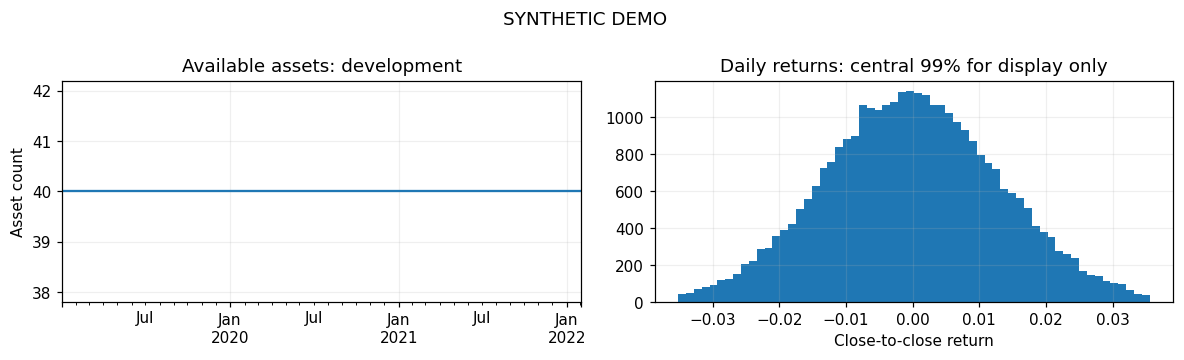

,,absolute_return_correlation
asset,asset,
Asset_003,Asset_015,0.346904
Asset_015,Asset_034,0.322483
Asset_012,Asset_015,0.321684
Asset_008,Asset_024,0.318456
Asset_015,Asset_024,0.317633
Asset_024,Asset_026,0.316502
Asset_026,Asset_039,0.314938
Asset_003,Asset_039,0.311251
Asset_008,Asset_025,0.309240


In [5]:
fig, axes = plt.subplots(1, 2, figsize=(11, 3.3))
close.loc[dev_dates].notna().sum(axis=1).plot(ax=axes[0], title='Available assets: development')
axes[0].set_ylabel('Asset count')
r = ret_1.loc[dev_dates].to_numpy().ravel()
r = r[np.isfinite(r)]
q = np.quantile(r, [0.005, 0.995])
axes[1].hist(r[(r >= q[0]) & (r <= q[1])], bins=60)
axes[1].set_title('Daily returns: central 99% for display only')
axes[1].set_xlabel('Close-to-close return')
fig.suptitle(MODE)
plt.tight_layout()
plt.show()

# Correlations require overlapping observed returns; no filling with zeros.
corr = ret_1.loc[dev_dates].corr(min_periods=60)
upper = corr.where(np.triu(np.ones(corr.shape), k=1).astype(bool)).stack()
display(upper.abs().nlargest(10).rename('absolute_return_correlation').to_frame())


**Investigate before interpreting performance:** confirm split/dividend adjustment across *all* OHLC
fields (not adjusted close mixed with raw open), volume conventions, identifiers, suspensions,
delistings, and point-in-time membership. If raw and adjusted close are both supplied, verify the
provider's factor and apply the appropriate transformation consistently; do not guess the factor.
Do not drop assets because their full-sample history later ends or their future liquidity is low.
Large moves can be real; bad ticks and corporate actions need source verification. Futures roll
jumps cannot be repaired by ordinary return winsorization.


## 4. Features, labels, and eligibility

Every feature below is known at close $t$. Rolling windows include today because execution starts
tomorrow. No extra shift is required for those features; the **target** shifts forward. Cross-sectional
ranks use only assets eligible on the current signal date. They are allowed because that day's
cross-section is observable at the assumed synchronized signal time.

| Feature family | Idea | Main failure mode |
|---|---|---|
| 1- and 5-session returns | Short-term reversal / continuation | News-driven trends, costs |
| 21/63-session momentum excluding latest 5 | Slow information diffusion | Crowded-trade reversals |
| 21/63-session volatility and high-low range | Risk and uncertainty | Changing volatility regimes |
| Intraday, overnight, close location, MA distance | Recent price pressure | Bid-ask noise and adjustment errors |
| Relative volume and trailing dollar volume | Attention and tradability | Volume definitions and capacity |

No asset identifier is used as a predictor. The model is pooled across assets; validation tests
**future dates for this universe**, not generalization to entirely unseen asset identities.


In [6]:
history_count = close.notna().rolling(WARMUP, min_periods=1).sum()
dollar_volume_21 = (close * volume).rolling(21, min_periods=15).mean()
eligible = (
    close.notna() & open_.notna() & high.notna() & low.notna() &
    volume.gt(0) & tradable & ~stale_5 &
    history_count.ge(MIN_HISTORY) & dollar_volume_21.ge(MIN_DOLLAR_VOLUME)
)

features_wide = {
    'ret_1': ret_1,
    'ret_5': close / close.shift(5) - 1,
    'mom_21_5': close.shift(5) / close.shift(21) - 1,
    'mom_63_5': close.shift(5) / close.shift(63) - 1,
    'vol_21': ret_1.rolling(21, min_periods=15).std(),
    'vol_63': ret_1.rolling(63, min_periods=40).std(),
    'range_1': (high - low) / close,
    'intraday': close / open_ - 1,
    'overnight': open_ / close.shift(1) - 1,
    'close_location': (close - low) / (high - low).replace(0, np.nan) - 0.5,
    'ma_distance_21': close / close.rolling(21, min_periods=15).mean() - 1,
    'relative_volume_21': volume / volume.rolling(21, min_periods=15).median() - 1,
    'log_volume_change': np.log1p(volume).diff(),
    'log_dollar_volume_21': np.log1p(dollar_volume_21),
}
features_wide['rank_ret_1'] = features_wide['ret_1'].where(eligible).rank(axis=1, pct=True) - 0.5
features_wide['rank_mom_21_5'] = features_wide['mom_21_5'].where(eligible).rank(axis=1, pct=True) - 0.5

# future_stack=True retains missing rows, avoiding future-dependent row deletion.
X_all = pd.DataFrame({name: frame.stack(future_stack=True)
                      for name, frame in features_wide.items()}).reindex(grid)
X_all = X_all.replace([np.inf, -np.inf], np.nan).astype('float32')
feature_cols = X_all.columns.tolist()
target_wide = open_.shift(-2) / open_.shift(-1) - 1
target = target_wide.stack(future_stack=True).reindex(grid).rename('target')
target = target.replace([np.inf, -np.inf], np.nan)

date_table = pd.DataFrame({'entry_date': calendar.to_series().shift(-1).to_numpy(),
                           'exit_date': calendar.to_series().shift(-2).to_numpy()}, index=calendar)
meta = pd.DataFrame(index=grid)
signal_dates = meta.index.get_level_values('date')
meta['entry_date'] = signal_dates.map(date_table['entry_date'])
meta['exit_date'] = signal_dates.map(date_table['exit_date'])
meta['eligible'] = eligible.stack(future_stack=True).reindex(grid).fillna(False)
meta['target'] = target

# Exclude only warm-up and the unobserved end of the evaluation window, not assets with missing future prices.
signal_calendar = calendar[WARMUP:-2]
prediction_mask = meta['eligible'] & signal_dates.isin(signal_calendar)
data = X_all.loc[prediction_mask].join(meta.loc[prediction_mask])
assert not data.index.duplicated().any()
assert (data.index.get_level_values('date') < data['entry_date']).all()
assert (data['entry_date'] < data['exit_date']).all()
print(f'{len(feature_cols)} features; {len(data):,} point-in-time eligible asset-days')
display(data.head(3))


16 features; 37,720 point-in-time eligible asset-days


ret_1     ret_5  mom_21_5  mom_63_5    vol_21    vol_63   range_1  intraday  overnight  close_location  \
date       asset                                                                                                                  
2019-04-01 Asset_000 -0.009622  0.005153  0.049026  0.002061  0.012271  0.012369  0.033026 -0.010771   0.001162       -0.166658   
           Asset_001  0.019087  0.015359  0.025218 -0.058875  0.011688  0.012991  0.020101  0.015983   0.003056        0.390443   
           Asset_002  0.007523  0.028069 -0.070065 -0.036159  0.013271  0.014100  0.030729  0.010786  -0.003229        0.171884   

                      ma_distance_21  relative_volume_21  log_volume_change  log_dollar_volume_21  rank_ret_1  rank_mom_21_5 entry_date  \
date       asset                                                                                                                          
2019-04-01 Asset_000        0.004131           -0.174976           1.134841             15.356461      -0.350           0.25 2019-04-02   
           Asset_001        0.020092           -0.109632          -0.224875             16.392977       0.350           0.10 2019-04-02   
           Asset_002       -0.018540            0.167118           0.651131             16.616144       0.075          -0.45 2019-04-02   

                      exit_date  eligible    target  
date       asset                                     
2019-04-01 Asset_000 2019-04-03      True  0.006356  
           Asset_001 2019-04-03      True -0.013732  
           Asset_002 2019-04-03      True -0.007206

,development_missing_fraction
ret_1,0.0
ret_5,0.0
mom_21_5,0.0
mom_63_5,0.0
vol_21,0.0
vol_63,0.0
range_1,0.0
intraday,0.0
overnight,0.0
close_location,0.0


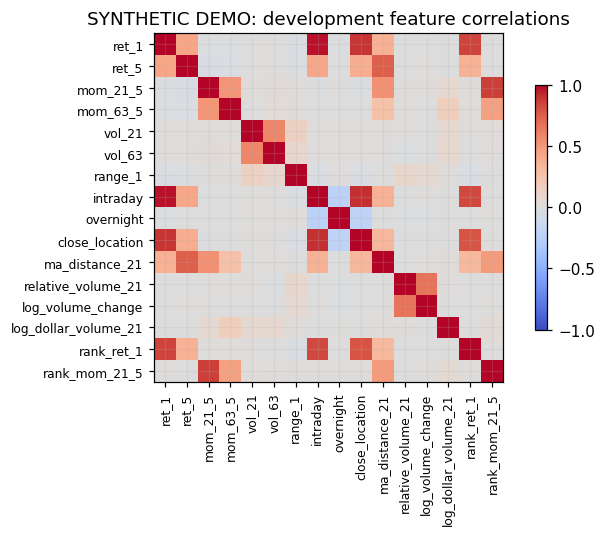

In [7]:
# Development feature diagnostics only. Do not use test outcomes for feature selection.
dev_data = data.loc[data.index.get_level_values('date') < test_start]
display(dev_data[feature_cols].isna().mean().sort_values(ascending=False)
        .rename('development_missing_fraction').to_frame().round(3))
fig, ax = plt.subplots(figsize=(7, 5))
im = ax.imshow(dev_data[feature_cols].corr(), vmin=-1, vmax=1, cmap='coolwarm')
ax.set_xticks(range(len(feature_cols)), feature_cols, rotation=90, fontsize=8)
ax.set_yticks(range(len(feature_cols)), feature_cols, fontsize=8)
fig.colorbar(im, ax=ax, shrink=0.7)
ax.set_title(f'{MODE}: development feature correlations')
plt.tight_layout()
plt.show()


## 5. Date-based validation and a small model comparison

Reserve the final 20% of dates. Inside development, use three expanding folds on **unique dates**,
then map those dates to every asset row. `gap=2` conservatively removes the two signal dates
immediately before validation. We additionally assert that every training label exits **before**
the first validation signal date. Validation labels must also end before the final test begins.

Fit once at the start of each fold and hold the model fixed through that validation block. This
matches the final fixed-model holdout. Daily feature updates do not use future information.
History from before a boundary is valid for constructing rolling features on the other side.

Compare two transparent signal baselines, two Ridge penalties, and one small histogram gradient
boosting model. Each rule is calibrated to return units using a training-only intercept and
nonnegative slope; its economic direction is fixed in advance. Ridge uses training-fold imputation and scaling. Trees use imputation without
scaling. Disable automatic random early-stopping validation in the tree; chronological outer
folds select its fixed settings. The zero-return forecast is an error benchmark, not a tradable signal.
Select the candidate with the highest equal-fold mean daily RankIC. Portfolio rules and costs are
fixed in advance; report their development performance before inspecting the final test.


In [8]:
dev_signal_dates = signal_calendar[signal_calendar < test_start]
splitter = TimeSeriesSplit(n_splits=N_FOLDS, gap=2)
folds, fold_info = [], []
row_dates = data.index.get_level_values('date')

for fold, (tr_dates_idx, va_dates_idx) in enumerate(splitter.split(dev_signal_dates), 1):
    train_dates = dev_signal_dates[tr_dates_idx]
    val_dates = dev_signal_dates[va_dates_idx]
    fit_date = val_dates.min()
    tr = np.flatnonzero(row_dates.isin(train_dates) & data['target'].notna() &
                        data['exit_date'].lt(fit_date))
    # Keep all point-in-time eligible validation rows, including unknown future labels.
    va = np.flatnonzero(row_dates.isin(val_dates) & data['exit_date'].lt(test_start))
    assert len(tr) > 0 and len(va) > 0
    assert data.iloc[tr]['exit_date'].max() < fit_date
    assert set(row_dates[tr]).isdisjoint(set(row_dates[va]))
    assert not data.iloc[tr][feature_cols].isna().all().any(), 'An entire training feature is missing.'
    folds.append((tr, va))
    fold_info.append({'fold': fold, 'train_start': row_dates[tr].min(),
                      'train_end': row_dates[tr].max(), 'max_train_label_exit': data.iloc[tr]['exit_date'].max(),
                      'validation_start': row_dates[va].min(), 'validation_end': row_dates[va].max(),
                      'train_rows': len(tr), 'validation_rows': len(va)})

fold_table = pd.DataFrame(fold_info)
display(fold_table)


,fold,train_start,train_end,max_train_label_exit,validation_start,validation_end,train_rows,validation_rows
0,1,2019-04-01,2019-12-16,2019-12-18,2019-12-19,2020-09-02,7440,7400
1,2,2019-04-01,2020-08-31,2020-09-02,2020-09-03,2021-05-19,14840,7400
2,3,2019-04-01,2021-05-17,2021-05-19,2021-05-20,2022-01-31,22240,7320


In [9]:
models = {
    'Ridge_10': make_pipeline(SimpleImputer(strategy='median'), StandardScaler(), Ridge(alpha=10)),
    'Ridge_1000': make_pipeline(SimpleImputer(strategy='median'), StandardScaler(), Ridge(alpha=1000)),
    'HistGB': make_pipeline(SimpleImputer(strategy='median'), HistGradientBoostingRegressor(
        max_iter=100, learning_rate=0.05, max_leaf_nodes=15, min_samples_leaf=100,
        l2_regularization=10, early_stopping=False, random_state=SEED)),
}
signal_baselines = {'Reversal_1d': ('ret_1', -1.0), 'Momentum_21_5': ('mom_21_5', 1.0)}

def rule_prediction(train, val, name):
    col, sign = signal_baselines[name]
    median = train[col].median()
    x = sign * train[col].fillna(median).to_numpy()
    y = train['target'].to_numpy()
    variance = np.mean((x - x.mean()) ** 2)
    slope = (max(0.0, np.mean((x - x.mean()) * (y - y.mean())) / variance)
             if np.ptp(x) > 0 and variance > 0 else 0.0)
    intercept = y.mean() - slope * x.mean()
    return intercept + slope * sign * val[col].fillna(median).to_numpy()

def daily_ic(frame):
    rows = []
    for date, day in frame.groupby(level='date', sort=True):
        z = day[['target', 'prediction']].dropna()
        if len(z) < MIN_ASSETS or z['prediction'].nunique() < 2 or z['target'].nunique() < 2:
            continue
        rows.append((date, z['prediction'].corr(z['target']),
                     z['prediction'].rank().corr(z['target'].rank())))
    return pd.DataFrame(rows, columns=['date', 'IC', 'RankIC']).set_index('date')

def prediction_metrics(frame):
    z = frame[['target', 'prediction']].dropna()
    ic = daily_ic(frame)
    if z.empty:
        raise ValueError('No labeled observations to score.')
    sse = ((z['target'] - z['prediction']) ** 2).sum()
    zero_sse = (z['target'] ** 2).sum()
    return {'RMSE': np.sqrt(mean_squared_error(z['target'], z['prediction'])),
            'MAE': mean_absolute_error(z['target'], z['prediction']),
            'OOS_R2_vs_zero': 1 - sse / zero_sse if zero_sse > 0 else np.nan,
            'mean_IC': ic['IC'].mean(), 'mean_RankIC': ic['RankIC'].mean(),
            'IC_days': len(ic), 'scored_rows': len(z),
            'unscored_rows': len(frame) - len(z)}

cv_rows, cv_predictions = [], []
for fold, (tr, va) in enumerate(folds, 1):
    train, val = data.iloc[tr], data.iloc[va]
    for name in list(signal_baselines) + list(models):
        if name in signal_baselines:
            pred = rule_prediction(train, val, name)
        else:
            estimator = clone(models[name])
            with threadpool_limits(limits=THREADS):
                estimator.fit(train[feature_cols], train['target'])
                pred = estimator.predict(val[feature_cols])
        result = val[['target', 'entry_date', 'exit_date']].copy()
        result['prediction'], result['model'], result['fold'] = pred, name, fold
        cv_predictions.append(result)
        cv_rows.append({'model': name, 'fold': fold, **prediction_metrics(result)})
    print(f'Fold {fold}/{N_FOLDS} complete')

cv_results = pd.DataFrame(cv_rows)
cv_predictions = pd.concat(cv_predictions)
cv_summary = cv_results.groupby('model').agg(
    mean_RankIC=('mean_RankIC', 'mean'), fold_RankIC_std=('mean_RankIC', 'std'),
    mean_IC=('mean_IC', 'mean'), RMSE=('RMSE', 'mean'), MAE=('MAE', 'mean'),
    OOS_R2_vs_zero=('OOS_R2_vs_zero', 'mean'))
cv_summary = cv_summary.sort_values('mean_RankIC', ascending=False)
selected_name = cv_summary.index[0]
assert np.isfinite(cv_summary.loc[selected_name, 'mean_RankIC'])
display(cv_summary.round(5))
print('Frozen candidate:', selected_name)
print('Rule baselines use training-only calibration; a zero slope produces no ranking signal.')


Fold 1/3 complete
Fold 2/3 complete
Fold 3/3 complete


,mean_RankIC,fold_RankIC_std,mean_IC,RMSE,MAE,OOS_R2_vs_zero
model,,,,,,
Reversal_1d,0.06539,0.00943,0.07406,0.01426,0.01130,0.00380
Ridge_1000,0.05733,0.00605,0.06361,0.01426,0.01131,0.00352
Ridge_10,0.05589,0.00601,0.06260,0.01426,0.01131,0.00336
HistGB,0.03443,0.02213,0.04394,0.01431,0.01134,-0.00310
Momentum_21_5,NaN,NaN,NaN,0.01429,0.01132,-0.00022


Frozen candidate: Reversal_1d
Rule baselines use training-only calibration; a zero slope produces no ranking signal.


## 6. Portfolio construction, costs, and development checks

For each signal date, equally weight the top and bottom prediction groups at $+0.5$ and $-0.5$
total notional. Use enough names per side to satisfy the configured weight cap. Ties use the
asset identifier as a reproducible tie-breaker. If fewer than `MIN_ASSETS` are eligible or all
scores are identical, hold cash.
Weights depend only on that day's predictions, never on the availability of future returns.

The target weights are fractions of **pre-rebalance NAV**. Cash absorbs costs. Before each rebalance,
mark existing holdings using realized returns to obtain drifted weights $\widetilde w_t$. Then

$$T_t=\sum_i|w_{i,t}-\widetilde w_{i,t}|,\qquad
R_t^{net}=\sum_i w_{i,t}y_{i,t}-cT_t-b_t,$$

$$\widetilde w_{i,t+1}=\frac{w_{i,t}(1+y_{i,t})}{1+R_t^{net}}.$$

$c$ is one-way commission/spread/slippage per absolute dollar traded. A portfolio with gross
exposure 1 costs 5 bps to enter when `COST_BPS=5`. A complete sign reversal trades notional 2;
turnover is **not** divided by two. Include initial entry, terminal liquidation, and the configured
annual short-borrow rate, accrued by actual calendar days / 365. Gross returns use the same target
weights before costs. No cash interest, financing rebate, market impact, or availability model is
inferred from OHLCV. Dollar neutrality does not imply beta or sector neutrality.

If a held return is missing, stop and require a source correction or explicit execution/delisting
policy. Silently deleting that asset or filling its return with zero would bias the backtest.


In [10]:
def make_weights(prediction, dates):
    weights = pd.DataFrame(0.0, index=pd.DatetimeIndex(dates), columns=assets)
    for date, day in prediction.groupby(level='date', sort=True):
        if date not in weights.index:
            continue
        score = day['prediction'].droplevel('date').dropna()
        if len(score) < MIN_ASSETS or score.nunique() < 2:
            continue
        n_side = max(int(np.ceil(len(score) * TOP_FRACTION)),
                     int(np.ceil(0.5 / MAX_ABS_WEIGHT)))
        if 2 * n_side > len(score):
            continue
        ordered = score.rename('score').reset_index().sort_values(['score', 'asset'])
        weights.loc[date, ordered['asset'].iloc[:n_side]] = -0.5 / n_side
        weights.loc[date, ordered['asset'].iloc[-n_side:]] = 0.5 / n_side
    gross = weights.abs().sum(axis=1)
    assert weights.sum(axis=1).abs().max() < 1e-10
    assert (np.isclose(gross, 1) | np.isclose(gross, 0)).all()
    assert weights.abs().max().max() <= MAX_ABS_WEIGHT + 1e-10
    return weights

def backtest(weights, returns, cost_bps=COST_BPS, borrow_bps=BORROW_BPS_ANNUAL):
    weights = weights.sort_index()
    assert len(weights) > 0
    # Each next interval must start exactly when the previous interval ends.
    entries = date_table.loc[weights.index, 'entry_date']
    exits = date_table.loc[weights.index, 'exit_date']
    assert np.array_equal(entries.iloc[1:].to_numpy(), exits.iloc[:-1].to_numpy()), 'Nonconsecutive intervals.'
    realized = returns.reindex(index=weights.index, columns=weights.columns)
    missing_held = realized.isna() & weights.ne(0)
    if missing_held.any().any():
        bad = missing_held.stack()[lambda x: x].index.tolist()[:5]
        raise ValueError(f'Missing held returns; resolve fills/marks/delistings explicitly. Examples: {bad}')
    if (realized.where(weights.ne(0)) < -1).any().any():
        raise ValueError('Invalid simple return below -100%.')

    previous = np.zeros(weights.shape[1])
    records = []
    rate = cost_bps / 10000
    for k, date in enumerate(weights.index):
        w = weights.loc[date].to_numpy()
        r = realized.loc[date].fillna(0).to_numpy()  # only unheld missing marks may be zero
        traded = np.abs(w - previous).sum()
        days_held = (exits.loc[date] - entries.loc[date]).days
        borrow = borrow_bps / 10000 * days_held / 365 * np.abs(w[w < 0]).sum()
        gross = float(w @ r)
        trade_cost = rate * traded
        net = gross - trade_cost - borrow
        if k == len(weights) - 1:
            # Exit marked positions at the final open; normalized to this day's starting NAV.
            final_traded = np.abs(w * (1 + r)).sum()
            traded += final_traded
            trade_cost += rate * final_traded
            net -= rate * final_traded
        if 1 + net <= 0:
            raise ValueError('Strategy NAV exhausted; inspect data and leverage.')
        previous = w * (1 + r) / (1 + net)
        records.append({'signal_date': date, 'entry_date': entries.loc[date],
                        'exit_date': exits.loc[date], 'gross_return': gross, 'net_return': net,
                        'turnover': traded, 'trade_cost': trade_cost, 'borrow_cost': borrow,
                        'gross_exposure': np.abs(w).sum(), 'net_exposure': w.sum(),
                        'holdings': np.count_nonzero(w)})
    result = pd.DataFrame(records).set_index('exit_date')
    result['net_nav'] = (1 + result['net_return']).cumprod()
    result['gross_nav'] = (1 + result['gross_return']).cumprod()
    # Include initial NAV=1 so an initial loss counts toward drawdown.
    result['drawdown'] = result['net_nav'] / result['net_nav'].cummax().clip(lower=1) - 1
    return result

def performance(bt):
    r = bt['net_return']
    vol = r.std(ddof=1)
    return {'ann_return': np.prod(1 + r) ** (ANNUAL_DAYS / len(r)) - 1,
            'ann_vol': vol * np.sqrt(ANNUAL_DAYS),
            'Sharpe': r.mean() / vol * np.sqrt(ANNUAL_DAYS) if vol > 0 else np.nan,
            'max_drawdown': bt['drawdown'].min(), 'mean_turnover': bt['turnover'].mean(),
            'mean_trade_cost_bps': bt['trade_cost'].mean() * 10000,
            'mean_borrow_cost_bps': bt['borrow_cost'].mean() * 10000,
            'active_day_fraction': bt['gross_exposure'].gt(0).mean()}


In [11]:
# Evaluate development trading for the predeclared candidate set. Reset capital/holdings per fold.
cv_portfolio_rows = []
for (name, fold), pred in cv_predictions.groupby(['model', 'fold']):
    dates = pd.date_range(pred.index.get_level_values('date').min(),
                          pred.index.get_level_values('date').max(), freq='D')
    dates = calendar[calendar.isin(dates)]
    weights = make_weights(pred, dates)
    bt = backtest(weights, target_wide)
    cv_portfolio_rows.append({'model': name, 'fold': fold, **performance(bt)})
cv_portfolio = pd.DataFrame(cv_portfolio_rows)
development_trading = cv_portfolio.groupby('model')[['Sharpe', 'ann_return', 'max_drawdown', 'mean_turnover']].mean()
display(development_trading.reindex(cv_summary.index).round(4))
display(cv_results.loc[cv_results['model'].eq(selected_name), ['fold', 'mean_RankIC', 'mean_IC', 'RMSE']].round(5))
print('Selection remains the frozen RankIC rule; no test-based parameter or sign changes.')
print('Negative development net returns are a valid outcome; they do not establish deployable alpha.')


,Sharpe,ann_return,max_drawdown,mean_turnover
model,,,,
Reversal_1d,2.1997,0.1090,-0.0215,1.5740
Ridge_1000,1.7998,0.0865,-0.0190,1.3619
Ridge_10,1.7659,0.0851,-0.0189,1.3483
HistGB,-0.5736,-0.0253,-0.0543,1.3556
Momentum_21_5,NaN,0.0000,0.0000,0.0000


,fold,mean_RankIC,mean_IC,RMSE
0,1,0.05859,0.06544,0.01421
5,2,0.07616,0.08163,0.01410
10,3,0.06143,0.07512,0.01446


Selection remains the frozen RankIC rule; no test-based parameter or sign changes.
Negative development net returns are a valid outcome; they do not establish deployable alpha.


In [12]:
# Validation permutation importance: diagnose the selected learned model without using test labels.
if selected_name in models:
    tr, va = folds[-1]
    train, val = data.iloc[tr], data.iloc[va]
    importance_model = clone(models[selected_name])
    check_val = val.loc[val['target'].notna()]
    if len(check_val) > 5000:
        check_val = check_val.sample(5000, random_state=SEED)
    with threadpool_limits(limits=THREADS):
        importance_model.fit(train[feature_cols], train['target'])
        pi = permutation_importance(importance_model, check_val[feature_cols], check_val['target'],
                                    scoring='neg_mean_squared_error', n_repeats=3, random_state=SEED)
    importance = pd.DataFrame({'feature': feature_cols, 'MSE_increase': pi.importances_mean,
                               'repeat_std': pi.importances_std}).sort_values('MSE_increase', ascending=False)
    display(importance.head(10))
else:
    importance = pd.DataFrame()
    print('Selected transparent rule:', signal_baselines[selected_name])


Selected transparent rule: ('ret_1', -1.0)


Permutation importance here measures the increase in validation MSE when a feature is shuffled.
It is diagnostic, not a causal effect or a new selection rule. Correlated features can share or
mask importance; low importance alone is not a reason to delete a feature. Do not revise the
feature set after observing the final test without reserving a new holdout.


## 7. Locked final test and robustness

Refit the selected model using development labels whose exits precede the first test signal date.
Freeze it for the entire holdout, matching the fold procedure. Predictions are generated for every
point-in-time eligible test row, including rows whose future target is missing. Forecast metrics
report their labeled subset; portfolio execution enforces complete marks for held assets.

Inspect test results once. The cost scenarios below are sensitivity analysis of **fixed predictions
and weights**, not an opportunity to select a more flattering strategy. Sharpe is a descriptive
statistic here; correlated returns, multiple model trials, and a short sample limit inference.


In [13]:
test_dates = signal_calendar[signal_calendar >= test_start]
final_train_mask = (row_dates < test_start) & data['exit_date'].lt(test_start) & data['target'].notna()
test_mask = row_dates.isin(test_dates)
final_train, final_test = data.loc[final_train_mask], data.loc[test_mask]
assert len(final_train) and len(final_test)
assert final_train['exit_date'].max() < test_dates.min()
assert not final_train[feature_cols].isna().all().any()

if selected_name in models:
    final_model = clone(models[selected_name])
    with threadpool_limits(limits=THREADS):
        final_model.fit(final_train[feature_cols], final_train['target'])
        final_prediction = final_model.predict(final_test[feature_cols])
else:
    final_model = None
    final_prediction = rule_prediction(final_train, final_test, selected_name)

test_predictions = final_test[['target', 'entry_date', 'exit_date']].copy()
test_predictions['prediction'] = final_prediction
zero_predictions = test_predictions.copy()
zero_predictions['prediction'] = 0.0
test_prediction_metrics = pd.DataFrame({
    selected_name: prediction_metrics(test_predictions),
    'Zero_forecast': prediction_metrics(zero_predictions),
}).T
display(test_prediction_metrics.round(5))
test_ic = daily_ic(test_predictions)
test_weights = make_weights(test_predictions, test_dates)
test_bt = backtest(test_weights, target_wide)
test_performance = pd.Series(performance(test_bt), name='test')
display(test_performance.round(5).to_frame())


,RMSE,MAE,OOS_R2_vs_zero,mean_IC,mean_RankIC,IC_days,scored_rows,unscored_rows
Reversal_1d,0.01403,0.01116,0.0053,0.08231,0.07141,200.0,8000.0,0.0
Zero_forecast,0.01407,0.01119,0.0000,NaN,NaN,0.0,8000.0,0.0


,test
ann_return,0.15835
ann_vol,0.04755
Sharpe,3.11559
max_drawdown,-0.02291
mean_turnover,1.57259
mean_trade_cost_bps,7.86295
mean_borrow_cost_bps,0.19178
active_day_fraction,1.00000


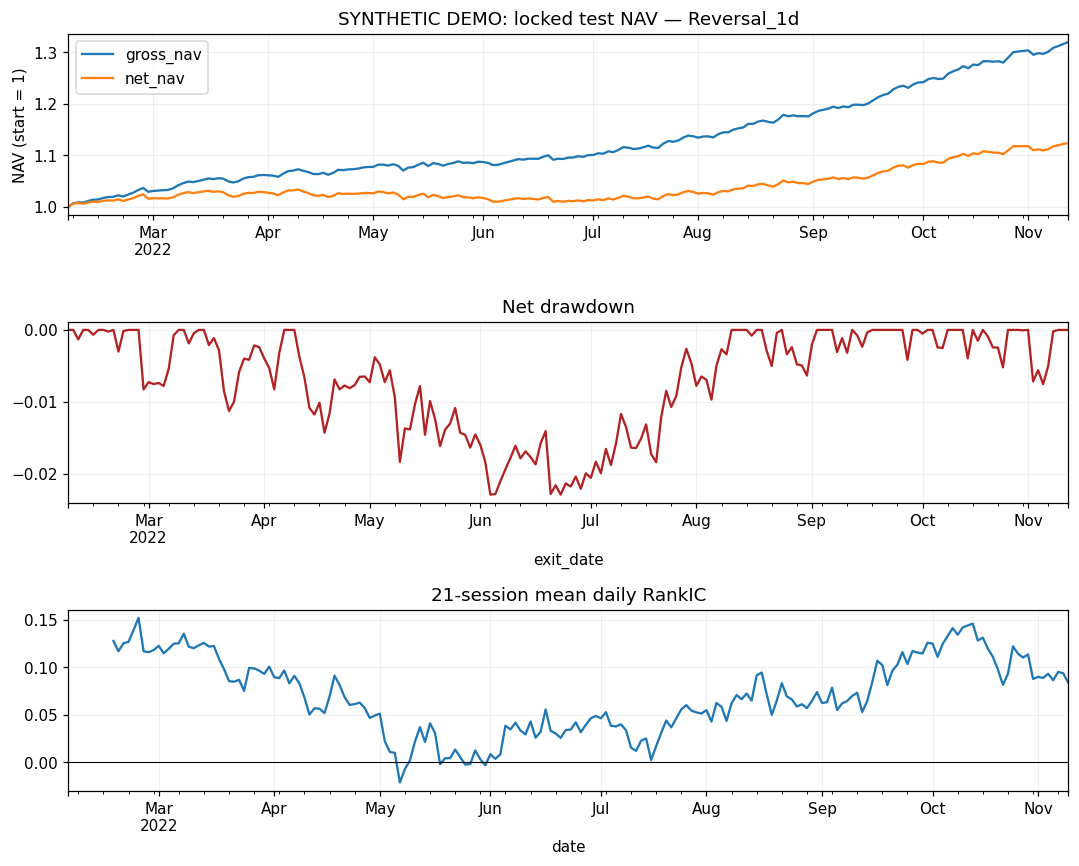

In [14]:
fig, axes = plt.subplots(3, 1, figsize=(10, 8))
start = date_table.loc[test_dates[0], 'entry_date']
nav_plot = pd.concat([pd.DataFrame({'gross_nav': [1.0], 'net_nav': [1.0]}, index=[start]),
                      test_bt[['gross_nav', 'net_nav']]])
nav_plot.plot(ax=axes[0], title=f'{MODE}: locked test NAV — {selected_name}')
axes[0].set_ylabel('NAV (start = 1)')
test_bt['drawdown'].plot(ax=axes[1], color='firebrick', title='Net drawdown')
test_ic['RankIC'].rolling(21, min_periods=10).mean().plot(ax=axes[2], title='21-session mean daily RankIC')
axes[2].axhline(0, color='black', linewidth=0.7)
plt.tight_layout()
plt.show()


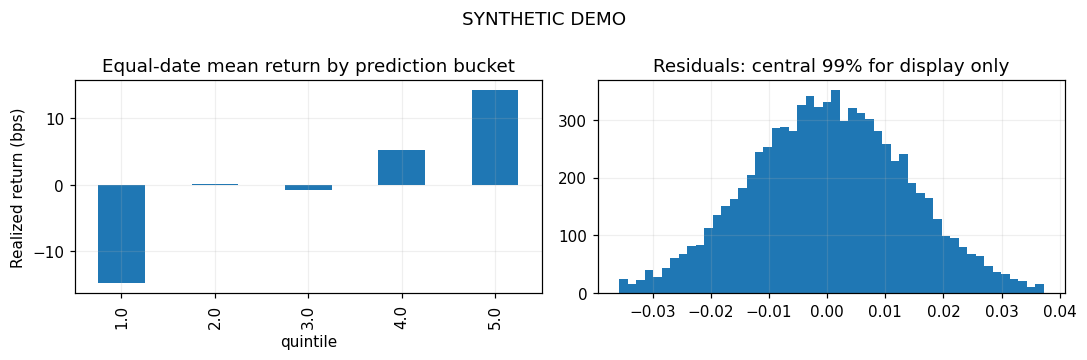

,days,ann_return,ann_vol,Sharpe,max_drawdown,mean_turnover,mean_trade_cost_bps,mean_borrow_cost_bps,active_day_fraction
year,,,,,,,,,
2022,200,0.1583,0.0476,3.1156,-0.0229,1.5726,7.863,0.1918,1.0


Yearly drawdown below uses the full test peak; annualized returns for partial years are descriptive.


,ann_return,ann_vol,Sharpe,max_drawdown,mean_turnover,mean_trade_cost_bps,mean_borrow_cost_bps,active_day_fraction
one_way_cost_bps,,,,,,,,
0.0,0.4119,0.0476,7.2785,-0.0114,1.5720,0.0000,0.1918,1.0
2.0,0.3045,0.0476,5.6149,-0.0123,1.5722,3.1444,0.1918,1.0
5.0,0.1583,0.0476,3.1156,-0.0229,1.5726,7.8630,0.1918,1.0
10.0,-0.0500,0.0476,-1.0539,-0.0855,1.5732,15.7321,0.1918,1.0
20.0,-0.3616,0.0478,-9.3653,-0.3029,1.5745,31.4891,0.1918,1.0


Borrow remains charged even in the zero execution-cost scenario.


In [15]:
# Quintile outcomes are a forecast diagnostic, not a second backtest.
bucket = test_predictions[['target', 'prediction']].copy()
bucket['percentile'] = bucket.groupby(level='date')['prediction'].rank(pct=True, method='average')
bucket['quintile'] = np.ceil(bucket['percentile'] * 5).clip(1, 5)
bucket_daily = bucket.groupby([pd.Grouper(level='date'), 'quintile'])['target'].mean()
bucket_mean = bucket_daily.groupby('quintile').mean()
fig, axes = plt.subplots(1, 2, figsize=(10, 3.3))
bucket_mean.mul(10000).plot.bar(ax=axes[0], title='Equal-date mean return by prediction bucket')
axes[0].set_ylabel('Realized return (bps)')
residual = (test_predictions['target'] - test_predictions['prediction']).dropna()
lo, hi = residual.quantile([0.005, 0.995])
axes[1].hist(residual.loc[residual.between(lo, hi)], bins=50)
axes[1].set_title('Residuals: central 99% for display only')
fig.suptitle(MODE)
plt.tight_layout()
plt.show()

year_rows = []
for year, part in test_bt.groupby(test_bt.index.year):
    year_rows.append({'year': year, 'days': len(part), **performance(part)})
display(pd.DataFrame(year_rows).set_index('year').round(4))
print('Yearly drawdown below uses the full test peak; annualized returns for partial years are descriptive.')

sensitivity = []
for cost in [0.0, 2.0, 5.0, 10.0, 20.0]:
    scenario = backtest(test_weights, target_wide, cost_bps=cost, borrow_bps=BORROW_BPS_ANNUAL)
    sensitivity.append({'one_way_cost_bps': cost, **performance(scenario)})
display(pd.DataFrame(sensitivity).set_index('one_way_cost_bps').round(4))
print('Borrow remains charged even in the zero execution-cost scenario.')


Additional checks worth discussing if time remains: compare independent historical regimes;
test a one-extra-session execution delay; examine asset/sector contribution and beta exposure;
replace constant costs with spreads, ADV participation, and asset-specific borrow estimates.
The one-way cost grid does not estimate capacity. Mixed currencies, asynchronous closes,
halts, and incomplete delisting marks need separate treatment before this backtest is meaningful.


## 8. Findings, exports, and interview explanation

Use the printed summary as a first draft, then add economic interpretation after running the
actual data. A valid conclusion can be that prediction quality is too weak or turnover is too costly.
Do not treat the best of a small candidate set as proof of an exploitable effect.


In [16]:
rank_ic = test_prediction_metrics.loc[selected_name, 'mean_RankIC']
stats = performance(test_bt)
print(f'DATA: {MODE}')
print(f'Selected on development RankIC: {selected_name}')
print(f'Locked test: {test_dates.min().date()} to {test_dates.max().date()} (signal dates)')
print(f'Mean daily RankIC: {rank_ic:.4f}')
print(f'Net annualized return: {stats["ann_return"]:.2%}; net Sharpe: {stats["Sharpe"]:.2f}')
print(f'Maximum drawdown: {stats["max_drawdown"]:.2%}; average turnover: {stats["mean_turnover"]:.3f}')
print(f'Execution cost: {COST_BPS:g} bps one way; annual borrow: {BORROW_BPS_ANNUAL:g} bps')
if USE_DEMO:
    print('These are synthetic software-validation outputs, not a market research finding.')
elif stats['ann_return'] <= 0 or rank_ic <= 0:
    print('The holdout does not support this strategy under the stated assumptions.')
else:
    print('Positive descriptive results require regime, execution, and capacity validation before use.')


DATA: SYNTHETIC DEMO
Selected on development RankIC: Reversal_1d
Locked test: 2022-02-03 to 2022-11-09 (signal dates)
Mean daily RankIC: 0.0714
Net annualized return: 15.83%; net Sharpe: 3.12
Maximum drawdown: -2.29%; average turnover: 1.573
Execution cost: 5 bps one way; annual borrow: 100 bps
These are synthetic software-validation outputs, not a market research finding.


In [17]:
OUTPUT_DIR.mkdir(parents=True, exist_ok=True)
test_predictions.reset_index().to_csv(OUTPUT_DIR / 'test_predictions.csv', index=False)
test_weights.to_csv(OUTPUT_DIR / 'test_weights.csv', index_label='signal_date')
test_bt.to_csv(OUTPUT_DIR / 'test_backtest.csv')
cv_results.to_csv(OUTPUT_DIR / 'cv_prediction_metrics.csv', index=False)
cv_portfolio.to_csv(OUTPUT_DIR / 'cv_portfolio_metrics.csv', index=False)
fold_table.to_csv(OUTPUT_DIR / 'validation_folds.csv', index=False)
test_prediction_metrics.to_csv(OUTPUT_DIR / 'test_prediction_metrics.csv')
if not importance.empty:
    importance.to_csv(OUTPUT_DIR / 'validation_feature_importance.csv', index=False)
summary = {'mode': MODE, 'selected_model': selected_name, 'seed': SEED,
           'target': 'open[t+2] / open[t+1] - 1', 'test_start': str(test_start.date()),
           'feature_columns': feature_cols, 'cost_bps': COST_BPS,
           'borrow_bps_annual': BORROW_BPS_ANNUAL, 'test_performance': stats,
           'assumptions': REAL_DATA_CHECKS, 'python': platform.python_version(),
           'pandas': pd.__version__, 'numpy': np.__version__, 'sklearn': sklearn.__version__}
(OUTPUT_DIR / 'run_summary.json').write_text(json.dumps(summary, indent=2), encoding='utf-8')
print('Saved prediction, portfolio, validation, and summary files to:', OUTPUT_DIR.resolve())


Saved prediction, portfolio, validation, and summary files to: /workspace/scratch/2dc5ec9bde6f/work/market_project_outputs


**A concise interview explanation**

“I first clarified when the signal is known and where the strategy can execute. I converted prices
to returns without filling missing prices and checked adjustments, duplicated dates, and stale
bars. I used a small set of momentum, reversal, volatility, and volume features. I compared simple
rules, Ridge, and a small tree model using expanding date folds with label purging. I selected on
development RankIC and inspected the final period only after freezing the setup. The portfolio
uses explicit long/short weights and charges costs on drift-adjusted turnover. My final assessment
depends on both predictive stability and net performance after costs.”

**Before submitting:** replace synthetic outputs; resolve source-quality flags; verify assumptions;
state the actual selected model and main numerical results; explain one economic mechanism and
one failure mode; distinguish empirical results from execution assumptions. A negative result is
preferable to an inflated backtest.

**Implementation references**

- [scikit-learn: data leakage and preprocessing pipelines](https://scikit-learn.org/stable/common_pitfalls.html)
- [scikit-learn: TimeSeriesSplit and its gap parameter](https://scikit-learn.org/stable/modules/generated/sklearn.model_selection.TimeSeriesSplit.html)
- [scikit-learn: histogram gradient boosting](https://scikit-learn.org/stable/modules/generated/sklearn.ensemble.HistGradientBoostingRegressor.html)

The splitting and accounting choices above are explicit research assumptions; the software
references document the APIs, not the profitability or realism of the strategy.
